# Backtest USD/CLP — estrategia M1 Ridge con histéresis DH

Entrega del jueves 12 de noviembre de 2026.

- **Estrategia:** M1 (regresión logística Ridge) con histéresis DH, q = 0,20, posiciones −1, 0 y +1.
- **Carry:** overnight, FEDL01 rezagada menos TPM. **Costo:** 2 pb por unidad de cambio de posición.
- **Datos:** Bloomberg hasta el 6 de noviembre de 2026. Este notebook **no usa la base**: lee solo archivos de `resultados/`.
- **Sin simulación:** no hay datos sintéticos ni números aleatorios; todo sale de las salidas guardadas del modelo congelado.

## 1. Modelos y supuestos

- **Variables:** 13 series del núcleo, incluido el cobre HG1.
- **Modelo:** regresión logística Ridge con C = 0,01, estandarizada con datos previos al entrenamiento.
- **Reentreno:** ventana expansiva desde 2000-08-01, cada 20 jornadas.
- **Calibración:** Platt en línea, solo con predicciones previas.
- **Señal:** percentil de la probabilidad cruda sobre las últimas 63 predicciones. Entra en +1 si es ≥ 0,80 y en −1 si es ≤ 0,20; sale a 0 al cruzar 0,50.
- **M2 y M3:** M2 (LightGBM) y M3 (promedio) existen en `03_modelos_decision.py`, pero no forman parte de la estrategia final.

## 2. Mecanismo de ejecución

La decisión se toma con información hasta el cierre de la jornada *t* y la posición se aplica al retorno del USD/CLP de *t* a *t*+1, al cierre observado (`PX_LAST`).

**Pendiente de confirmar:** el horario de cierre de las series frente a VIX, DXY y UST2Y. Si se confirma un sesgo de horario, esas series se rezagarán y el modelo se reentrenará con el cambio declarado.

## 3. Período

- **Validación: del 1 de enero de 2018 al 27 de septiembre de 2024** (la primera jornada con datos es el 2 de enero de 2018; los títulos y tablas usan las fechas reales). Todas las cifras principales de este notebook son de este tramo.
- **El tramo fuera de muestra (desde el 1 de octubre de 2024) no se ha evaluado todavía.**
- El desarrollo completo (2010 a 2024) aparece más abajo como tabla secundaria.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RES = Path("resultados")
INICIO_VAL, FIN_VAL = "2018-01-01", "2024-09-27"
COSTO_PB = 2.0      # pb por unidad de cambio de posición
ANIO = 252          # jornadas por año

diaria = pd.read_csv(RES / "conviccion_diaria.csv", parse_dates=["fecha"]).sort_values("fecha").reset_index(drop=True)
valor_total = pd.read_csv(RES / "conviccion_valor_total.csv")

requeridas = ["fecha", "ret_next", "posicion", "acierto", "pnl_bruto_pb", "costo_pb", "pnl_neto_pb", "carry_pb"]
faltan = [c for c in requeridas if c not in diaria.columns]
assert not faltan, f"Faltan columnas en conviccion_diaria.csv: {faltan}"
print("Columnas de conviccion_diaria.csv:", list(diaria.columns))
print("Columnas de conviccion_valor_total.csv:", list(valor_total.columns))
print(f"Filas: {len(diaria)}; desde {diaria.fecha.min().date()} hasta {diaria.fecha.max().date()}")

Columnas de conviccion_diaria.csv: ['fecha', 'ret_next', 'p_cruda', 'p_calibrada', 'posicion', 'percentil_63', 'x_fedl01', 'x_tpm', 'dias_next', 'acierto', 'carry_pb', 'pnl_bruto_pb', 'costo_pb', 'pnl_neto_pb']
Columnas de conviccion_valor_total.csv: ['estrategia', 'jornadas', 'total_pb', 'media_por_jornada_pb', 'ic95_lo', 'ic95_hi']
Filas: 3504; desde 2010-04-01 hasta 2024-09-27


In [2]:
# Cambio de posición sobre la serie completa (así el primer día de la validación hereda la posición de 2017)
diaria["dpos"] = diaria["posicion"].diff().abs()
diaria.loc[0, "dpos"] = abs(diaria.loc[0, "posicion"])

# Comprar siempre (+1): retorno del USD/CLP más el carry de una posición larga, sin costos salvo la entrada
diaria["pnl_siempre_pb"] = diaria["ret_next"] * 1e4 + diaria["carry_pb"]

val = diaria[(diaria.fecha >= INICIO_VAL) & (diaria.fecha <= FIN_VAL)].copy()
dev = diaria.copy()   # desarrollo completo

# Fechas reales del tramo de validación, tomadas de los datos (se usan en títulos y tablas)
INI_VAL = val.fecha.min().strftime("%Y-%m-%d")
FIN_VAL_REAL = val.fecha.max().strftime("%Y-%m-%d")

# Comprar siempre sobre la serie completa: costo de entrada de 2 pb en la primera jornada
siempre_dev = diaria["pnl_siempre_pb"].copy()
siempre_dev.iloc[0] -= COSTO_PB
print(f"Validación: {len(val)} jornadas, {val.fecha.min().date()} a {val.fecha.max().date()}")
print(f"Desarrollo: {len(dev)} jornadas, {dev.fecha.min().date()} a {dev.fecha.max().date()}")

Validación: 1714 jornadas, 2018-01-02 a 2024-09-27
Desarrollo: 3504 jornadas, 2010-04-01 a 2024-09-27


In [3]:
def metricas(pnl_pb, acierto, pct_cero, operaciones):
    """Métricas sobre pnl diario en pb del nocional (suma aritmética)."""
    r = pnl_pb.to_numpy() / 1e4
    media_anual = r.mean() * ANIO
    vol_anual = r.std(ddof=1) * np.sqrt(ANIO)
    acum = np.concatenate([[0.0], np.cumsum(r)])
    max_dd = (acum - np.maximum.accumulate(acum)).min()
    return {
        "Retorno anual neto (%)": 100 * media_anual,
        "Volatilidad anual (%)": 100 * vol_anual,
        "Sharpe": media_anual / vol_anual,
        "Drawdown máximo (% del nocional)": 100 * max_dd,
        "Acierto en días con posición (%)": 100 * acierto,
        "Días en 0 (%)": 100 * pct_cero,
        "Operaciones (suma de |Δposición|)": operaciones,
        "Jornadas": len(r),
    }

def tabla(df):
    # Comprar siempre: costo de entrada de 2 pb el primer día; carry incluido
    siempre = df["pnl_siempre_pb"].copy()
    siempre.iloc[0] -= COSTO_PB
    m = metricas(df["pnl_neto_pb"], df["acierto"].mean(), (df["posicion"] == 0).mean(), df["dpos"].sum())
    s = metricas(siempre, (df["ret_next"] > 0).mean(), 0.0, 1.0)
    return pd.DataFrame({"M1 · DH (q 0,20)": m, "Comprar siempre (+1)": s})

tabla_val = tabla(val)
tabla_dev = tabla(dev)

## 4. Curva acumulada neta y posición (validación)

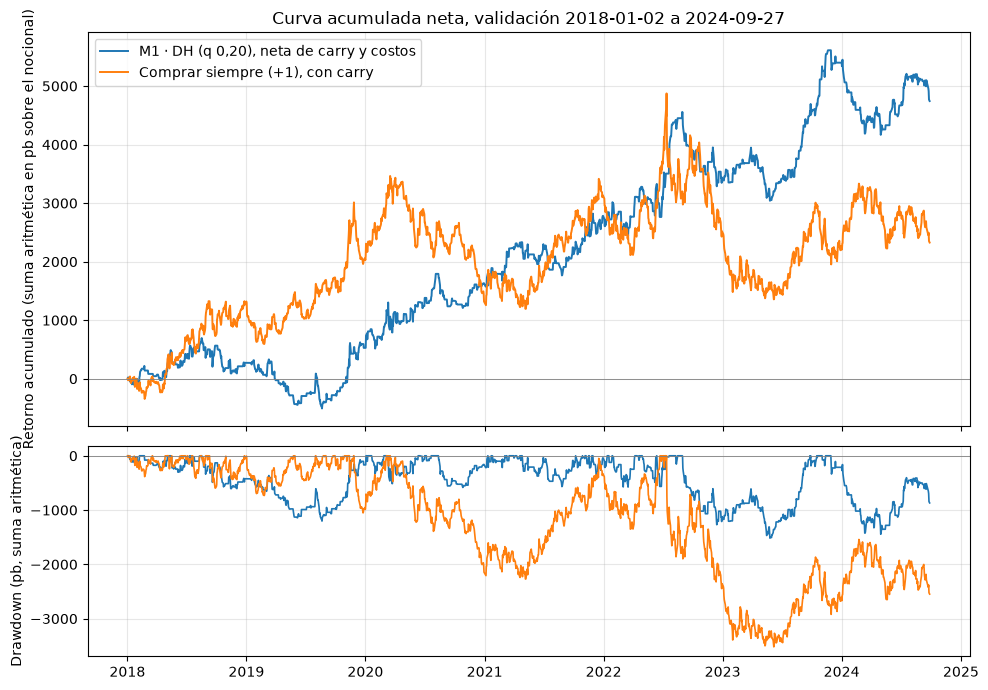

Drawdown máximo (pb): {'M1 · DH (q 0,20), neta de carry y costos': -1516.3, 'Comprar siempre (+1), con carry': -3518.4}


In [4]:
siempre_val = val["pnl_siempre_pb"].copy()
siempre_val.iloc[0] -= COSTO_PB
curva = pd.DataFrame({
    "M1 · DH (q 0,20), neta de carry y costos": val["pnl_neto_pb"].cumsum().to_numpy(),
    "Comprar siempre (+1), con carry": siempre_val.cumsum().to_numpy(),
}, index=val["fecha"])

def drawdown_pb(c):
    """Curva menos su máximo previo (el máximo parte en 0, el inicio de la curva)."""
    return c - np.maximum.accumulate(np.maximum(c.to_numpy(), 0.0))

dd = curva.apply(drawdown_pb)

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.6]})
for c in curva.columns:
    ax.plot(curva.index, curva[c], label=c, lw=1.4)
ax.axhline(0, color="grey", lw=0.6)
ax.set_title(f"Curva acumulada neta, validación {INI_VAL} a {FIN_VAL_REAL}")
ax.set_ylabel("Retorno acumulado (suma aritmética en pb sobre el nocional)")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
for c in dd.columns:
    ax2.plot(dd.index, dd[c], lw=1.2)
ax2.axhline(0, color="grey", lw=0.6)
ax2.set_ylabel("Drawdown (pb, suma aritmética)")
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("Drawdown máximo (pb):", dd.min().round(1).to_dict())

La ventaja del modelo no es uniforme. Entre 2018 y 2020 comprar siempre queda por encima de la estrategia, y el modelo llega a estar bajo cero en 2019. La mayor diferencia aparece desde 2022, y el drawdown de 2022 a 2023 es el episodio que más pesa en la tabla.

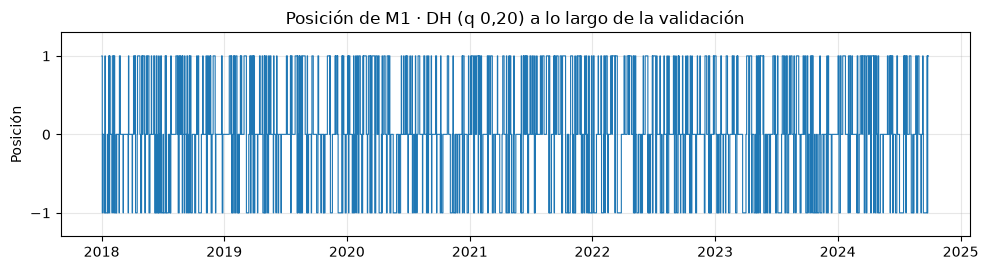

In [5]:
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.step(val["fecha"], val["posicion"], where="post", lw=0.8)
ax.set_yticks([-1, 0, 1])
ax.set_ylim(-1.3, 1.3)
ax.set_title("Posición de M1 · DH (q 0,20) a lo largo de la validación")
ax.set_ylabel("Posición")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Métricas (validación)

Retorno y volatilidad anualizados con 252 jornadas; retorno neto de carry y de costos de 2 pb. Comprar siempre incluye el carry de la posición larga y el costo de entrada. Las fechas del tramo se imprimen sobre la tabla, calculadas desde los datos.

In [6]:
print(f"Validación: {INI_VAL} a {FIN_VAL_REAL} ({len(val)} jornadas)")
tabla_val.round(3)

Validación: 2018-01-02 a 2024-09-27 (1714 jornadas)


,"M1 · DH (q 0,20)",Comprar siempre (+1)
Retorno anual neto (%),6.975,3.421
Volatilidad anual (%),9.932,14.051
Sharpe,0.702,0.243
Drawdown máximo (% del nocional),-15.163,-35.184
Acierto en días con posición (%),54.436,50.583
Días en 0 (%),46.558,0.000
Operaciones (suma de |Δposición|),1014.000,1.000
Jornadas,1714.000,1714.000


### Tabla secundaria: desarrollo completo (2010-04-01 a 2024-09-27)

Incluye el tramo de selección y la validación. Es una referencia secundaria, no la cifra principal.

In [7]:
tabla_dev.round(3)

,"M1 · DH (q 0,20)",Comprar siempre (+1)
Retorno anual neto (%),9.967,0.673
Volatilidad anual (%),9.028,12.254
Sharpe,1.104,0.055
Drawdown máximo (% del nocional),-15.163,-35.184
Acierto en días con posición (%),54.766,49.886
Días en 0 (%),45.548,0.000
Operaciones (suma de |Δposición|),2145.000,1.000
Jornadas,3504.000,3504.000


### Resultado neto por año calendario (2010 a 2024)

PnL neto en pb sobre el nocional (suma aritmética), de la estrategia y de comprar siempre. 2024 llega hasta el 27 de septiembre. La última fila compara los totales con `conviccion_valor_total.csv`.

In [8]:
from IPython.display import display

anual = pd.DataFrame({
    "año": diaria["fecha"].dt.year,
    "estrategia": diaria["pnl_neto_pb"],
    "comprar siempre": siempre_dev,
}).groupby("año").sum()
anual["diferencia"] = anual["estrategia"] - anual["comprar siempre"]
display(anual.round(1))

vt = valor_total.set_index("estrategia")["total_pb"]
chequeo = pd.DataFrame({
    "suma anual (pb)": [anual["estrategia"].sum(), anual["comprar siempre"].sum()],
    "conviccion_valor_total.csv (pb)": [vt["modelo"], vt["comprar_siempre"]],
}, index=["estrategia", "comprar siempre"])
chequeo["diferencia (pb)"] = chequeo["suma anual (pb)"] - chequeo["conviccion_valor_total.csv (pb)"]
display(chequeo.round(3))

,estrategia,comprar siempre,diferencia
año,,,
2010,1448.6,-1259.3,2707.9
2011,1793.3,650.8,1142.5
2012,1156.7,-1431.1,2587.8
2013,1471.3,616.7,854.5
2014,632.2,985.6,-353.4
2015,1592.9,1209.9,383.0
2016,1454.0,-988.9,2442.8
2017,-433.5,-1176.6,743.1
2018,272.4,1272.3,-999.9


,suma anual (pb),conviccion_valor_total.csv (pb),diferencia (pb)
estrategia,13859.518,13859.518,0.000
comprar siempre,936.197,936.374,-0.177


**Lectura del chequeo.** La suma anual de la estrategia coincide con el total del archivo (diferencia de 0,000 pb). La de comprar siempre queda **0,18 pb por debajo** (936,20 frente a 936,37 pb en 3.504 jornadas, 0,02 %). No es redondeo: los CSV guardan varios decimales y el redondeo no alcanza esa magnitud. La diferencia es la misma que ya aparecía en la verificación anterior, no viene de la agrupación por años, y no pude identificar su causa con los archivos de `resultados/`. Lo más probable es una diferencia en cómo `conviccion_valor_total.csv` trata el costo de entrada de comprar siempre (aquí 2 pb en la primera jornada); no la ajusté.

## 6. Verificación cruzada

Se comparan las cifras de la validación calculadas aquí con las guardadas en `resultados/modelos_decision.xlsx` (hoja `estrategias_validacion`, costo 2 pb) y con `metodologia_v2.md` §8.3 (Sharpe 0,702; 6,98 % anual). No se ajusta nada para que coincidan.

In [9]:
xl = pd.read_excel(RES / "modelos_decision.xlsx", sheet_name="estrategias_validacion")
xl = xl[xl["costo_pb"] == 2].set_index("estrategia")

filas = []
for nombre, clave, col in [("M1 · DH (q 0,20)", "M1_ridge|DH_histeresis_q0.2", "M1 · DH (q 0,20)"),
                           ("Comprar siempre (+1)", "REF_siempre_+1", "Comprar siempre (+1)")]:
    f = xl.loc[clave]
    filas.append({
        "estrategia": nombre,
        "Sharpe notebook": tabla_val.loc["Sharpe", col],
        "Sharpe xlsx": f["sharpe"],
        "Retorno anual % notebook": tabla_val.loc["Retorno anual neto (%)", col],
        "Retorno anual % xlsx": 100 * f["media_anual"],
        "Drawdown % notebook": tabla_val.loc["Drawdown máximo (% del nocional)", col],
        "Drawdown % xlsx": 100 * f["max_drawdown"],
        "Acierto % notebook": tabla_val.loc["Acierto en días con posición (%)", col],
        "Acierto % xlsx": 100 * f["acierto_dias_activos"],
        "Jornadas xlsx": int(f["n"]),
    })
cruce = pd.DataFrame(filas).set_index("estrategia")
cruce.loc["M1 · DH (q 0,20)", "Sharpe §8.3"] = 0.702
cruce.loc["M1 · DH (q 0,20)", "Retorno anual % §8.3"] = 6.98
cruce.round(4).T

estrategia,"M1 · DH (q 0,20)",Comprar siempre (+1)
Sharpe notebook,0.7023,0.2435
Sharpe xlsx,0.7024,0.2435
Retorno anual % notebook,6.9749,3.4212
Retorno anual % xlsx,6.9778,3.4211
Drawdown % notebook,-15.1633,-35.1839
Drawdown % xlsx,-15.1633,-35.1834
Acierto % notebook,54.4359,50.5834
Acierto % xlsx,54.2576,50.5834
Jornadas xlsx,1714.0000,1714.0000
Sharpe §8.3,0.7020,NaN


### Lectura de la verificación

Las cifras **coinciden salvo diferencias de redondeo**; no se ajustó nada.

- **Sharpe y retorno anual de M1·DH:** 0,7023 y 6,975 % aquí, frente a 0,7024 y 6,978 % en el xlsx y a 0,702 y 6,98 % en §8.3. La diferencia (0,0001 de Sharpe, 0,003 puntos de retorno) viene de que el notebook parte de las columnas ya redondeadas de `conviccion_diaria.csv` (por ejemplo, `pnl_bruto_pb` difiere hasta 0,005 pb de `posicion × (ret_next × 10⁴ + carry_pb)`), mientras el xlsx se calculó con la serie sin redondear.
- **Drawdown máximo:** −15,16 % en ambos.
- **Acierto en días con posición:** 54,44 % aquí frente a 54,26 % en el xlsx. La columna `acierto` del CSV deja vacíos 3 de los 916 días con posición (retorno exactamente cero); el xlsx los cuenta como fallos. Es una diferencia de definición.
- **Operaciones:** la suma de |Δposición| es 1.014 en la validación, igual que la suma de `costo_pb` dividida por 2 pb. Sin embargo, `costo_pb` está imputado a días distintos de 2 pb × |Δposición| de ese día (por ejemplo, la salida a 0 se cobra el día de la entrada anterior). Los totales coinciden; solo cambia la trayectoria diaria, y el drawdown no se ve afectado al cuarto decimal.
- **Comprar siempre frente a `conviccion_valor_total.csv`:** 936,2 pb aquí frente a 936,4 pb en el archivo (0,18 pb en 3.504 jornadas, 0,02 %). No identifiqué la causa exacta; es consistente con una diferencia mínima en el tratamiento del costo de entrada.

### Consistencia con `conviccion_valor_total.csv`

Totales acumulados en pb sobre las 3.504 jornadas del desarrollo completo.

In [10]:
total_modelo = diaria["pnl_neto_pb"].sum()
cmp = valor_total[valor_total["estrategia"].isin(["modelo", "comprar_siempre", "no_operar"])][["estrategia", "jornadas", "total_pb"]].copy()
cmp["total_notebook_pb"] = [total_modelo, siempre_dev.sum(), 0.0]
cmp["diferencia_pb"] = cmp["total_notebook_pb"] - cmp["total_pb"]
cmp.round(3)

,estrategia,jornadas,total_pb,total_notebook_pb,diferencia_pb
0,modelo,3504,13859.518,13859.518,0.000
1,comprar_siempre,3504,936.374,936.197,-0.177
2,no_operar,3504,0.000,0.000,0.000


## 7. Reservas

- **Costos:** se supone 2 pb por unidad de cambio de posición. **Todavía no se tienen los costos de la base del kit**; con 5 pb el Sharpe de M1·DH cae a ~0,25 (`metodologia_v2.md` §8).
- **q = 0,20 se eligió sobre los mismos datos** en que se evalúa el modelo, así que las cifras son una **cota superior** del desempeño esperable.
- **Los tramos y las operaciones no son independientes:** las posiciones persisten por la histéresis y las jornadas vecinas comparten información, por lo que los intervalos y valores p tratados como independientes subestiman la incertidumbre.
- **Carry del kit pendiente:** el carry usado es una aproximación (FEDL01 rezagada menos TPM). Cuando llegue el carry del kit las cifras cambiarán; la diferencia relevante se espera en el tramo fuera de muestra.
- **Fuera de muestra sin evaluar:** el tramo desde el 1 de octubre de 2024 no forma parte de ninguna cifra de este notebook.